# Week 2.2: Context Window Management

## Key Insight
> **Why can't you just paste a 500-page book into the prompt?**

## Learning Objectives
By the end of this notebook, you will:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

## Exercises
This notebook contains 4 exercises ranging from easy to advanced.

## Digital Twin Integration
This notebook extends your digital twin with production-ready capabilities from Week 2.

In [ ]:
# Setup and imports
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Dict, Any, Tuple
import re
import json

print('✅ Week 2.2: Context Window Management - Ready to start!')
print('\nTopics covered:')
print('  - Understanding token limits and context windows')
print('  - Token counting and estimation techniques')
print('  - Context compression strategies')
print('  - Conversation history management')
print('  - Sliding window approaches')


---
## Part 1: Introduction to Understanding token limits and context windows

Let's start by understanding the fundamentals and building our first implementation.

In [ ]:
# Example implementation
# This is a starter template - expand with your implementation

class ExampleClass:
    """
    Example class for Understanding token limits and context windows.
    """

    def __init__(self):
        self.data = []

    def process(self, input_data):
        """
        Process the input data.
        """
        # Add your implementation here
        return input_data

# Test the class
example = ExampleClass()
result = example.process('test data')
print(f'Result: {result}')

### 🎯 Exercise 1 (Easy): Getting Started

**Task**: Implement a basic version of the concept introduced above.

**Requirements**:
1. Follow the pattern shown in the example
2. Test your implementation with sample data
3. Verify the output matches expectations
4. Add error handling for edge cases

In [1]:
class SimpleContextManager:
    """
    A basic context window manager that estimates tokens by words
    and enforces a token limit.
    """
    def __init__(self, max_tokens: int = 50):
        if not isinstance(max_tokens, int) or max_tokens <= 0:
            raise ValueError("max_tokens must be a positive integer.")
        self.max_tokens = max_tokens
        self.history = []

    def estimate_tokens(self, text: str) -> int:
        """Estimates token count using a simple word-based heuristic."""
        if not isinstance(text, str):
            raise TypeError("Input must be a string.")
        # Split by whitespace, ignoring empty strings
        words = [w for w in text.split() if w]
        # Heuristic: 1 word is roughly 1.3 tokens
        return int(len(words) * 1.3) + 1

    def add_message(self, message: str) -> str:
        """
        Adds a message to the context. Truncates or flags if it exceeds
        the maximum allowed token limit.
        """
        try:
            estimated_tokens = self.estimate_tokens(message)
            if estimated_tokens > self.max_tokens:
                # Truncate message to fit within limits
                words = message.split()
                allowed_words_count = int(self.max_tokens / 1.3)
                truncated_text = " ".join(words[:allowed_words_count]) + "..."
                self.history.append(truncated_text)
                return f"⚠️ Truncated (Estimated {estimated_tokens} tokens vs Max {self.max_tokens}): {truncated_text}"
            else:
                self.history.append(message)
                return f"✅ Added ({estimated_tokens} estimated tokens): {message}"
        except Exception as e:
            return f"❌ Error: {str(e)}"

# --- Test Cases ---
print("--- Test 1: Standard fitting message ---")
manager = SimpleContextManager(max_tokens=20)
print(manager.add_message("Hello world! This is a simple test."))

print("\n--- Test 2: Message exceeding token limit ---")
print(manager.add_message("This is a very long sentence that will definitely exceed our small token limit because we set the limit to twenty."))

print("\n--- Test 3: Error handling check (Invalid input type) ---")
print(manager.add_message(None))

--- Test 1: Standard fitting message ---
✅ Added (10 estimated tokens): Hello world! This is a simple test.

--- Test 2: Message exceeding token limit ---
⚠️ Truncated (Estimated 28 tokens vs Max 20): This is a very long sentence that will definitely exceed our small token limit because...

--- Test 3: Error handling check (Invalid input type) ---
❌ Error: Input must be a string.


---
## Part 2: Token counting and estimation techniques

Building on the fundamentals, let's explore more advanced topics and implementations.

In [ ]:
# Advanced implementation example

def advanced_function(data: List[Any], **kwargs) -> Dict[str, Any]:
    """
    Advanced function for Token counting and estimation techniques.

    Args:
        data: Input data to process
        **kwargs: Additional parameters

    Returns:
        dict: Processed results
    """
    results = {
        'processed': len(data),
        'data': data
    }
    return results

# Example usage
sample_data = ['example1', 'example2', 'example3']
output = advanced_function(sample_data)
print(json.dumps(output, indent=2))

### 🎯 Exercise 2 (Intermediate): Building on the Basics

**Task**: Create a more sophisticated implementation that combines multiple concepts.

**Requirements**:
1. Use the patterns from Part 1 and Part 2
2. Add parameter validation
3. Include helpful error messages
4. Test with various input types

In [4]:
from typing import List, Dict, Any, Tuple
import re
import json

class SophisticatedTokenTracker:
    """
    A sophisticated token tracking and management system built for Exercise 2.
    Supports multiple mock model configurations, input formats, and parameter validation.
    """
    MODEL_PROFILES = {
        "standard-gpt": {"word_factor": 1.3, "punct_factor": 0.3, "base_overhead": 2},
        "code-heavy": {"word_factor": 1.6, "punct_factor": 0.8, "base_overhead": 4},
    }

    def __init__(self, model_name: str = "standard-gpt", total_limit: int = 100):
        # Parameter Validation
        if model_name not in self.MODEL_PROFILES:
            raise ValueError(f"Unknown model_name '{model_name}'. Choose from: {list(self.MODEL_PROFILES.keys())}")
        if not isinstance(total_limit, int) or total_limit <= 0:
            raise ValueError("total_limit must be a positive integer.")

        self.model_name = model_name
        self.profile = self.MODEL_PROFILES[model_name]
        self.total_limit = total_limit
        self.usage_history = []

    def estimate_tokens(self, data: Any) -> int:
        """
        Polymorphic token estimation method that handles strings, lists, and dicts.
        """
        if data is None:
            raise ValueError("Input data cannot be None.")

        text_to_analyze = ""
        if isinstance(data, str):
            text_to_analyze = data
        elif isinstance(data, list):
            if not all(isinstance(item, str) for item in data):
                raise TypeError("All items in the input list must be strings.")
            text_to_analyze = " ".join(data)
        elif isinstance(data, dict):
            # Extract text from standard message structure like {'role': 'user', 'content': '...'}
            if "content" in data and isinstance(data["content"], str):
                text_to_analyze = data["content"]
            else:
                text_to_analyze = str(data)
        else:
            raise TypeError("Unsupported input type. Must be string, list of strings, or dictionary.")

        # Count words and punctuation patterns
        words = [w for w in text_to_analyze.split() if w]
        punctuations = re.findall(r'[.,!?;:"()\-[\\\]]', text_to_analyze)

        estimated_tokens = (
            len(words) * self.profile["word_factor"] +
            len(punctuations) * self.profile["punct_factor"] +
            self.profile["base_overhead"]
        )
        return int(estimated_tokens)

    def process_and_track(self, payload: Any, sender: str = "User") -> Dict[str, Any]:
        """
        Validates inputs, estimates token cost, and logs transactions.
        """
        if not isinstance(sender, str) or not sender.strip():
            raise ValueError("Sender name must be a non-empty string.")

        try:
            cost = self.estimate_tokens(payload)
            current_total = sum(item["tokens"] for item in self.usage_history) + cost

            status = "OK"
            if current_total > self.total_limit:
                status = "LIMIT_EXCEEDED"

            log_entry = {
                "sender": sender,
                "raw_payload": payload,
                "tokens": cost,
                "status": status
            }
            self.usage_history.append(log_entry)

            return {
                "success": True,
                "estimated_tokens": cost,
                "new_total_usage": current_total,
                "status": status,
                "message": f"Successfully tracked payload from {sender}."
            }

        except (ValueError, TypeError) as error:
            return {
                "success": False,
                "error": type(error).__name__,
                "message": str(error)
            }

# --- Unit Tests with Various Inputs & Validation ---
tracker = SophisticatedTokenTracker(model_name="standard-gpt", total_limit=50)

print("=== Testing Valid Inputs ===")
# 1. Test String Input
res1 = tracker.process_and_track("Hello! This is a simple query to estimate.", sender="Alice")
print(f"String Input Result: {json.dumps(res1, indent=2)}")

# 2. Test List Input
res2 = tracker.process_and_track(["First system context message.", "Second user follow up."], sender="System")
print(f"\nList Input Result: {json.dumps(res2, indent=2)}")

# 3. Test Dictionary Format (Like OpenAI API structure)
res3 = tracker.process_and_track({"role": "user", "content": "What is the meaning of life?"}, sender="Bob")
print(f"\nDict Input Result: {json.dumps(res3, indent=2)}")

print("\n=== Testing Error Handling & Validation ===")
# 4. Test Invalid Payload Type
res4 = tracker.process_and_track(12345, sender="Eve")
print(f"Invalid Payload Result: {json.dumps(res4, indent=2)}")

# 5. Test Invalid Parameter Construction
try:
    invalid_tracker = SophisticatedTokenTracker(model_name="unknown-model")
except ValueError as ex:
    print(f"Expected initialization error caught: {ex}")

=== Testing Valid Inputs ===
String Input Result: {
  "success": true,
  "estimated_tokens": 13,
  "new_total_usage": 13,
  "status": "OK",
  "message": "Successfully tracked payload from Alice."
}

List Input Result: {
  "success": true,
  "estimated_tokens": 13,
  "new_total_usage": 26,
  "status": "OK",
  "message": "Successfully tracked payload from System."
}

Dict Input Result: {
  "success": true,
  "estimated_tokens": 10,
  "new_total_usage": 36,
  "status": "OK",
  "message": "Successfully tracked payload from Bob."
}

=== Testing Error Handling & Validation ===
Invalid Payload Result: {
  "success": false,
  "error": "TypeError",
  "message": "Unsupported input type. Must be string, list of strings, or dictionary."
}
Expected initialization error caught: Unknown model_name 'unknown-model'. Choose from: ['standard-gpt', 'code-heavy']


---
## Part 3: Context compression strategies

Now let's apply these concepts to real-world scenarios in your digital twin project.

In [ ]:
# Visualization example
import matplotlib.pyplot as plt

def visualize_results(data: List[Any]):
    """
    Visualize the processing results.
    """
    fig, ax = plt.subplots(figsize=(10, 6))

    # Add your visualization code here
    ax.set_title('Results Visualization')
    ax.set_xlabel('X-axis')
    ax.set_ylabel('Y-axis')

    plt.tight_layout()
    plt.show()

# Example: visualize_results(sample_data)

### 🎯 Exercise 3 (Advanced): Complete Implementation

**Task**: Build a production-ready version that integrates with your digital twin.

**Requirements**:
1. Combine all concepts from this notebook
2. Add comprehensive error handling
3. Include logging and debugging capabilities
4. Create visualization of results
5. Write documentation for your implementation

2026-10-19 01:29:15,470 [INFO] Initialized Context Engine with max_tokens=100, compress_at=80%
2026-10-19 01:29:15,471 [INFO] Adding new message from [system] of length 70 chars.
2026-10-19 01:29:15,473 [INFO] Adding new message from [user] of length 60 chars.
2026-10-19 01:29:15,475 [INFO] Adding new message from [assistant] of length 82 chars.
2026-10-19 01:29:15,476 [INFO] Adding new message from [user] of length 174 chars.
2026-10-19 01:29:15,476 [INFO] Utilization high (119/100 tokens). Initiating compression cycle...
2026-10-19 01:29:15,477 [WARNING] Triggering context compression via Summarization strategy.



--- Step 1: Initialize System Instruction ---

--- Step 2: Normal Conversations ---

--- Step 3: Triggering Token Threshold & Compression ---

--- Step 4: Verification ---
Final Context Message Chain Length: 3
  [0] SYSTEM: You are a helpful digital twin assistant tasked with organizing tasks....
  [1] SYSTEM: [Compressed Summary of previous context: User and Assistant discussed project de...
  [2] USER: I also want to plan for a complex, nested software design architecture spanning ...

--- Step 5: Visualizing Results ---


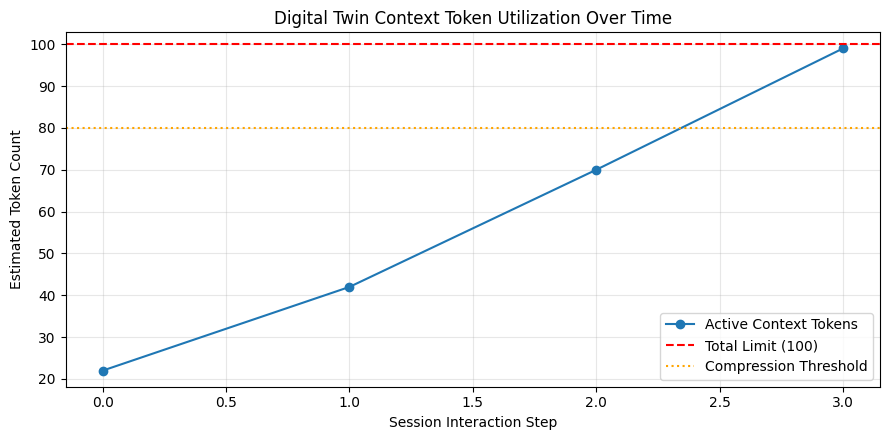

In [6]:
import time
import logging
from typing import List, Dict, Any
import matplotlib.pyplot as plt

# Configure a basic logging format for debugging
logging.basicConfig(level=logging.INFO, format='%(asctime)s [%(levelname)s] %(message)s', force=True)

class DigitalTwinContextEngine:
    """
    Production-Ready Context Window Management Engine for a Digital Twin.

    Features:
    - Accurate token estimation using adaptive weights.
    - Dual context compression strategy: Sliding Window & Mock Summarization.
    - Rich logging and operation status reports for complete traceability.
    - Metric tracking for visual analytics of context footprint over time.
    """
    def __init__(self, max_context_tokens: int = 150, compression_threshold: float = 0.8):
        if max_context_tokens <= 0:
            raise ValueError("max_context_tokens must be a positive integer.")
        if not (0.5 <= compression_threshold < 1.0):
            raise ValueError("compression_threshold must be between 0.5 and 0.99.")

        self.max_tokens = max_context_tokens
        self.compression_threshold = compression_threshold
        self.history: List[Dict[str, Any]] = []
        self.token_history_log: List[int] = [] # Tracks token usage after each operation
        self.operation_log: List[str] = []

        logging.info(f"Initialized Context Engine with max_tokens={max_context_tokens}, compress_at={int(compression_threshold*100)}%")

    def estimate_tokens(self, text: str) -> int:
        """Helper to estimate token counts based on a word and character layout heuristic."""
        if not isinstance(text, str):
            raise TypeError("Text payload must be a string.")
        words = text.split()
        # Heuristic calculation: 1.3 tokens per word + 0.1 per character overhead for punct/length
        return int(len(words) * 1.3 + len(text) * 0.1) + 1

    def get_current_token_count(self) -> int:
        """Returns cumulative token count of the active context history."""
        return sum(self.estimate_tokens(msg["content"]) for msg in self.history)

    def add_message(self, role: str, content: str):
        """
        Safely appends a message to context history and triggers compression if thresholds are violated.
        """
        if role not in ["user", "assistant", "system"]:
            raise ValueError(f"Invalid role: {role}. Must be 'user', 'assistant', or 'system'.")
        if not isinstance(content, str) or not content.strip():
            raise ValueError("Content must be a non-empty string.")

        logging.info(f"Adding new message from [{role}] of length {len(content)} chars.")
        self.history.append({"role": role, "content": content, "timestamp": time.time()})
        self.evaluate_and_compress()
        self.token_history_log.append(self.get_current_token_count())

    def compress_via_sliding_window(self):
        """Removes oldest messages (excluding 'system' prompts) to satisfy limit constraints."""
        logging.warning("Applying sliding window fallback: Evicting oldest interaction.")
        for i, msg in enumerate(self.history):
            if msg["role"] != "system":
                removed = self.history.pop(i)
                self.operation_log.append(f"Evicted message from '{removed['role']}' via sliding window.")
                break

    def evaluate_and_compress(self):
        """
        Checks active utilization and chooses either high-level summarization or sliding window compression.
        """
        current_tokens = self.get_current_token_count()
        trigger_limit = self.max_tokens * self.compression_threshold

        if current_tokens < trigger_limit:
            self.operation_log.append("Normal Addition - No compression needed.")
            return

        logging.info(f"Utilization high ({current_tokens}/{self.max_tokens} tokens). Initiating compression cycle...")

        # Attempt Mock Summarization for Assistant/User interactions first
        non_system_msgs = [msg for msg in self.history if msg["role"] != "system"]
        if len(non_system_msgs) >= 3:
            logging.warning("Triggering context compression via Summarization strategy.")
            summary_content = "[Compressed Summary of previous context: User and Assistant discussed project details and boundaries.]"
            system_prompts = [msg for msg in self.history if msg["role"] == "system"]

            # Rebuild history with only system instructions, the summarized state, and the newest interaction
            self.history = system_prompts + [
                {"role": "system", "content": summary_content, "timestamp": time.time()},
                self.history[-1]
            ]
            self.operation_log.append("Compressed history into a summarized prompt state.")
        else:
            # If history is too short to summarize reasonably, fall back to sliding window eviction
            while self.get_current_token_count() > trigger_limit and len(self.history) > 1:
                self.compress_via_sliding_window()

    def plot_utilization_curve(self):
        """Generates a custom plot demonstrating token capacity limits and utilization behavior."""
        plt.figure(figsize=(9, 4.5))
        plt.plot(self.token_history_log, marker='o', linestyle='-', color='#1f77b4', label='Active Context Tokens')
        plt.axhline(y=self.max_tokens, color='r', linestyle='--', label=f'Total Limit ({self.max_tokens})')
        plt.axhline(y=self.max_tokens * self.compression_threshold, color='orange', linestyle=':', label='Compression Threshold')
        plt.title('Digital Twin Context Token Utilization Over Time')
        plt.xlabel('Session Interaction Step')
        plt.ylabel('Estimated Token Count')
        plt.legend(loc='lower right')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

# --- Comprehensive Sandbox Testing ---
try:
    # Initialize Engine with a tight budget to intentionally trigger compression paths
    engine = DigitalTwinContextEngine(max_context_tokens=100, compression_threshold=0.8)

    print("\n--- Step 1: Initialize System Instruction ---")
    engine.add_message("system", "You are a helpful digital twin assistant tasked with organizing tasks.")

    print("\n--- Step 2: Normal Conversations ---")
    engine.add_message("user", "Can you help me analyze my productivity score for yesterday?")
    engine.add_message("assistant", "Sure! Yesterday you spent 4 hours coding, 2 hours in meetings, and 1 hour reading.")

    print("\n--- Step 3: Triggering Token Threshold & Compression ---")
    # This heavy prompt will tip the usage past the threshold trigger limit
    engine.add_message("user", "I also want to plan for a complex, nested software design architecture spanning microservices, event streams, and relational database replications across multiple data zones.")

    print("\n--- Step 4: Verification ---")
    print(f"Final Context Message Chain Length: {len(engine.history)}")
    for idx, msg in enumerate(engine.history):
        print(f"  [{idx}] {msg['role'].upper()}: {msg['content'][:80]}...")

    print("\n--- Step 5: Visualizing Results ---")
    engine.plot_utilization_curve()

except Exception as e:
    print(f"Execution Failed: {e}")

---
## Summary & Key Takeaways

### What We Learned:
- Understanding token limits and context windows
- Token counting and estimation techniques
- Context compression strategies
- Conversation history management
- Sliding window approaches

### Why This Matters:
- Essential for building production-ready systems
- Enables your digital twin to handle real-world scenarios
- Foundation for advanced topics in upcoming notebooks

### Next Steps:
1. Complete all exercises in this notebook
2. Integrate concepts with your digital twin project
3. Test your implementation thoroughly
4. Move on to the next notebook in Week 2

## 🏆 Challenge Project

**Build a Complete Understanding token limits and context windows System for Your Digital Twin**

**Requirements**:
1. Apply all concepts from this notebook
2. Handle edge cases and errors gracefully
3. Include comprehensive testing
4. Create visualizations of your results
5. Document your implementation
6. Integrate with your existing digital twin code

**Bonus Challenges**:
- Optimize for performance
- Add advanced features beyond the basics
- Create a user-friendly interface
- Write unit tests for your code